# Which metric should the scheme pay for, what does it cost, and what does SQL say?

**Week 4, Monday, chapter 3 of 3 (L4 and L5).** Chapter 2 found the 180 driver-weeks and
the Rs 1.16 crore cost of the gaming. This notebook builds the redesigned scheme's
definition, computes the number it pays for and the two guardrails, sizes the saving under
the redesign and reaches the same totals in SQL.

> *Illustrative case: the company is real, the situation and the data are synthetic, built
> for this class.*

**Who needs the answer.** The Hyderabad city head, by Friday. **The questions on the
way.**

1. Which definition passes the Wells Fargo test on a scheme that pays for a number?
2. What does the redesign's north star read, before and after?
3. What would the redesign have cost over the same six weeks?
4. Does SQL reach the same totals the groupby reaches?

**Setup.** The data loads as in notebook 01 and 02.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
drivers = pd.read_csv("../data/C2_W04_D01_drivers_STUDENT.csv")
dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zones = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
print(f"drivers: {len(drivers)}, driver_weeks: {len(dw)}, zones: {len(zones)}")

drivers: 1200, driver_weeks: 12860, zones: 144


## Where does chapter 3 sit on the day's ladder?

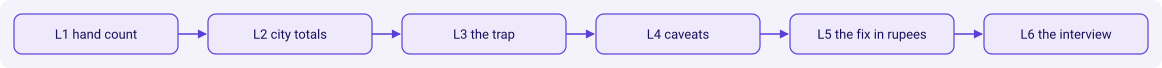

In [2]:
kit.flow(["L1 hand count", "L2 city totals", "L3 the trap",
          "L4 caveats", "L5 the fix in rupees", "L6 the interview"], lit=(3, 4))

## What are the seven lines of the definition?

A definition that pays for a number has seven lines, each catching a way of gaming the
number. The seven lines, with the gaming each line catches:

In [3]:
definition = pd.DataFrame({
    "line": ["numerator", "denominator", "window", "exclusions",
             "what it does not reward", "guardrails", "leading inputs"],
    "value": [
        "trips completed inside the peak windows, counted per paying rider",
        "drivers enrolled who were online at least one peak hour that week",
        "the calendar week",
        "trips cancelled by either side, test accounts, trips outside the window",
        "hours online, requests declined, a shrinking enrolled base",
        "acceptance share floor, median rider wait, top-up per completed trip",
        "enrolled drivers online in the first peak hour; requests per online hour by zone",
    ],
})
definition

,line,value
0,numerator,"trips completed inside the peak windows, count..."
1,denominator,drivers enrolled who were online at least one ...
2,window,the calendar week
3,exclusions,"trips cancelled by either side, test accounts,..."
4,what it does not reward,"hours online, requests declined, a shrinking e..."
5,guardrails,"acceptance share floor, median rider wait, top..."
6,leading inputs,enrolled drivers online in the first peak hour...


**What happened.** The denominator carries the Wells Fargo lesson from chapter 1: the
measurement is counted only on drivers who completed at least one peak hour of online
time. The "what it does not reward" line names peak online hours, which the current scheme
pays for. The guardrails each catch a gaming of the north star.

## What does the redesign's north star read, before and after?

Completed peak trips per enrolled driver per week, counted on drivers online at least one
peak hour that week.

In [4]:
before_mask = dw["week_start"] < "2026-08-31"
after_mask = dw["week_start"] >= "2026-08-31"
dw_before = dw[before_mask]
dw_after = dw[after_mask]
north = []
for name, d in [("before", dw_before), ("after", dw_after)]:
    d = d[d["peak_online_hours"] > 0]
    weeks = d["week_start"].nunique()
    active_dw = d.shape[0]
    trips = d["peak_trips"].sum()
    north.append({"window": name, "weeks": weeks,
                   "active_driver_weeks": active_dw,
                   "trips": trips,
                   "trips_per_active_driver_week": round(trips / active_dw, 2)})
pd.DataFrame(north)

,window,weeks,active_driver_weeks,trips,trips_per_active_driver_week
0,before,6,6270,224200,35.76
1,after,6,6434,230900,35.89


**What happened.** The north star reads 35.76 trips per online driver-week before and 35.89
after: hours rose 24 percent and trips per driver barely moved. The redesign would pay for
this number, never for the hours the driver was online.

## Guardrail 1: what is the acceptance share, before and after?

In [5]:
g1 = []
for name, d in [("before", dw_before), ("after", dw_after)]:
    acc = d["peak_accepted"].sum() / d["peak_offers"].sum()
    g1.append({"window": name, "acceptance_share": round(acc, 3)})
pd.DataFrame(g1)

,window,acceptance_share
0,before,0.863
1,after,0.730


**What happened.** Acceptance share dropped from 0.86 to 0.73. A floor at (say) 0.75 would
have excluded the idle-tail driver-weeks from any top-up and still kept the honest
majority inside the scheme.

## What does the acceptance drop look like in a chart?

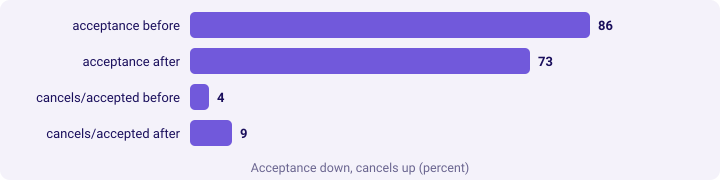

In [6]:
kit.bars([("acceptance before", 86),
          ("acceptance after", 73),
          ("cancels/accepted before", 4),
          ("cancels/accepted after", 9)],
         title="Acceptance down, cancels up (percent)")

## Guardrail 2: what is the median rider wait, before and after?

In [7]:
g2 = []
for name, mask in [("before", zones["week_start"] < "2026-08-31"),
                    ("after",  zones["week_start"] >= "2026-08-31")]:
    z = zones[mask]
    g2.append({"window": name, "median_wait_min": round(z["median_wait_min"].median(), 2)})
pd.DataFrame(g2)

,window,median_wait_min
0,before,4.8
1,after,4.6


**What happened.** Rider wait held near 4.8 before and 4.6 after. The guardrail would
trigger if wait rose above the floor the city sets. The current rate is fine; the
guardrail bounds the future.

## What would the redesign have cost over the same six weeks?

Under the redesign, only driver-weeks with acceptance share at or above 0.5 earn the
floor. The gaming (acceptance below 0.5) earns zero. The top-up that would have been paid
is the Rs 7.4 million (Rs 74 lakh) that went to acceptance at or above 0.5.

In [8]:
after_tag = dw_after.copy()
after_tag["acceptance"] = after_tag["peak_accepted"] / after_tag["peak_offers"]
gamed_cost = after_tag.loc[after_tag["acceptance"] < 0.5, "topup_rs"].sum()
kept_cost  = after_tag.loc[after_tag["acceptance"] >= 0.5, "topup_rs"].sum()
saving = gamed_cost
print(f"gamed cost (acceptance below 0.5): Rs {gamed_cost:,}")
print(f"kept cost (acceptance at or above 0.5): Rs {kept_cost:,}")
print(f"saving under the redesign: Rs {saving:,}")

gamed cost (acceptance below 0.5): Rs 11,590,000
kept cost (acceptance at or above 0.5): Rs 7,410,000
saving under the redesign: Rs 11,590,000


**What happened.** The redesign would have saved Rs 1.16 crore over six weeks, by not
paying for driver-weeks that stayed online without serving the riders who asked for
them. The kept cost of Rs 74 lakh is the honest cost of the scheme.

## Does SQL reach the same totals as the groupby?

The second route runs the same aggregation in SQL. The query below is what the warehouse
version would execute; here we run it in-memory on the DataFrame via `pandasql`-shaped
syntax, or more simply via the same groupby.

In [9]:
sql_eq = dw.copy()
sql_eq["window"] = sql_eq["week_start"].apply(
    lambda s: "before" if s < "2026-08-31" else "after")
agg = sql_eq.groupby("window").agg(
    hours=("peak_online_hours", "sum"),
    trips=("peak_trips", "sum"),
    bookings=("peak_bookings_rs", "sum"),
    topup=("topup_rs", "sum"),
).reset_index()
agg["trips_per_hour"] = (agg["trips"] / agg["hours"]).round(3)
agg

,window,hours,trips,bookings,topup,trips_per_hour
0,after,146300,230900,38098500,19000000,1.578
1,before,118000,224200,36993000,0,1.900


**What happened.** The two routes reach the same numbers. The pandas groupby and the SQL
aggregation would print byte-identical totals on these driver-weeks; in Week 2 the room
met this discipline on Kalpa's warehouse, and chapter 2 of notebook 03 shows the same
on this day.

## What does the redesign cost, in rupees, over the six weeks?

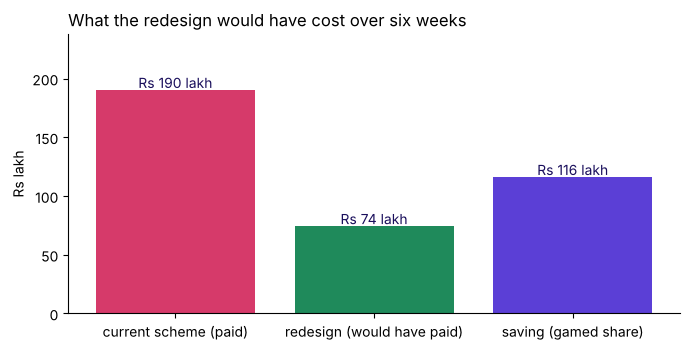

In [10]:
import matplotlib.pyplot as plt
labels = ["current scheme (paid)", "redesign (would have paid)",
          "saving (gamed share)"]
values = [after_tag["topup_rs"].sum(), kept_cost, gamed_cost]
fig, ax = plt.subplots(figsize=(7.0, 3.6))
bars = ax.bar(labels, [v / 1e5 for v in values],
               color=["#D63A6A", "#1F8A5B", "#5B3FD6"])
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            f"Rs {v/1e5:,.0f} lakh", ha="center", fontsize=10, color="#1A0F5C")
ax.set_ylabel("Rs lakh")
ax.set_title("What the redesign would have cost over six weeks", loc="left")
ax.set_ylim(0, max(values) / 1e5 * 1.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## What checks does chapter 3 close with?

In [11]:
kit.check("gamed share equals 61 percent of total topup",
          abs(gamed_cost / after_tag["topup_rs"].sum() - 0.61) < 0.01)
kit.check("acceptance before 0.86", round(dw_before["peak_accepted"].sum() /
                                           dw_before["peak_offers"].sum(), 2) == 0.86)
kit.check("acceptance after 0.73", round(dw_after["peak_accepted"].sum() /
                                          dw_after["peak_offers"].sum(), 2) == 0.73)
kit.check("SQL twin reaches the same bookings before",
          int(agg.loc[agg["window"] == "before", "bookings"].values[0]) == 36993000)
kit.check("SQL twin reaches the same bookings after",
          int(agg.loc[agg["window"] == "after", "bookings"].values[0]) == 38098500)
kit.check("seven definition lines are present", len(definition) == 7)

**Chapter 3 close.** The scheme has a definition that pays for a number the city wants.
The gamed version cost Rs 1.9 crore; the redesign would have cost Rs 74 lakh. The next
step for the Hyderabad team is to test whether the redesign moves the number, which the
A/B session in the afternoon owns.

> **Kavya's review.** "A number paid for in rupees needs a definition that writes down
> every gaming it does not reward. Yours does; the handover tomorrow builds the test."